# Фаза движения по сигналу акселерометра


## Параметры

Используем ширину сглаживания $h$, коэффициент RBF-ядра $\gamma$, радиус соседства $\varepsilon$, допуск на уменьшение фазы $\delta_\varphi$ и веса штрафов $\lambda_l$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA
from statsmodels.tsa.stattools import acf

DATA_PATH = 'data/long_walk_100_acc.csv'
START = 7174
N_SAMPLES = 9240
FS = 500
GRAVITY = 9.81
WINDOW = 500
ACF_MAX_LAG = 3 * FS
N_PHASES = 360
BANDWIDTH = 0.01
GAMMA = 1.0
EPSILON = 5.0
DELTA_PHI = np.pi / 12
LAMBDAS = np.array([1.0, 1.0, 1.0]) / 3

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

## 1. Сигнал

Рассматриваем $N$ отсчётов одного класса движения. Предполагается квазипериодичность сигнала с периодом $T$:

$$s_i=s_{[i+T]}+\epsilon_i,\tag{1}$$

По трём компонентам ускорения вычисляем сигнал:

$$s_i=\sqrt{a_{ix}^2+a_{iy}^2+a_{iz}^2}-g.\tag{2}$$

Требуется оценить фазу $\varphi_i\in[0,2\pi)$ каждого окна сигнала

In [2]:
data = pd.read_csv(DATA_PATH, sep=';', decimal=',').iloc[START:START + N_SAMPLES]
time = data['time'].to_numpy(dtype=float)
time = time - time[0]
axes = data[['X_value', 'Y_value', 'Z_value']].to_numpy(dtype=float)
signal = np.linalg.norm(axes, axis=1) - GRAVITY
signal

array([-1.77734982, -1.26693675, -0.73535504, ...,  5.70759079,
        6.24055971,  7.26570989], shape=(9240,))

## 2. Начальная оценка периода

Вычисляем автокорреляционную функцию:

$$\operatorname{ACF}(j)=
\frac{\sum_{i=0}^{N-j-1}(s_i-\bar s)(s_{i+j}-\bar s)}
{\sum_{i=0}^{N-1}(s_i-\bar s)^2},\qquad
\bar s=\frac1N\sum_{i=0}^{N-1}s_i.\tag{14}$$

Начальная оценка периода $T$ равна сдвигу, при котором достигается второй локальный максимум ACF

Длительность периода в секундах равна $T/\nu$, где $\nu$ обозначает частоту измерений.

Первый период: 461 отсчётов = 0.922 с


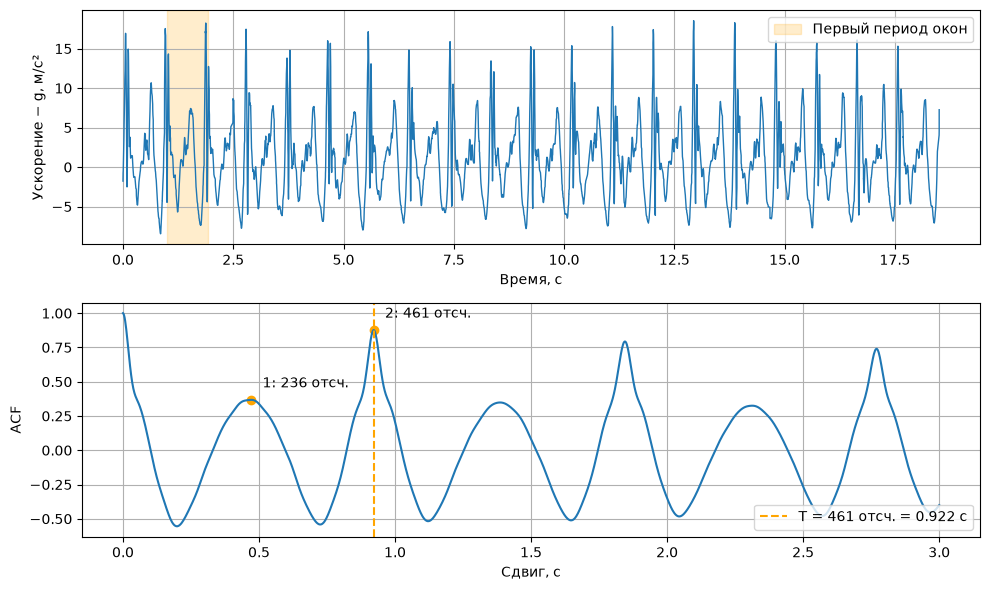

In [3]:
acf_values = acf(signal, nlags=min(ACF_MAX_LAG, len(signal) - 1), fft=True)
peaks, _ = find_peaks(acf_values)
peaks = peaks[peaks > 0]
period = int(peaks[1])
print(f'Первый период: {period} отсчётов = {period / FS:.3f} с')

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
axes[0].plot(time, signal, linewidth=1)
axes[0].axvspan(time[WINDOW - 1], time[WINDOW + period - 2], alpha=0.2,
                color='orange', label='Первый период окон')
axes[0].set(xlabel='Время, с', ylabel='Ускорение − g, м/с²')
axes[0].legend()

axes[1].plot(np.arange(len(acf_values)) / FS, acf_values)
axes[1].scatter(peaks[:2] / FS, acf_values[peaks[:2]], color='orange')
for number, peak in enumerate(peaks[:2], start=1):
    axes[1].annotate(f'{number}: {peak} отсч.',
                     (peak / FS, acf_values[peak]), xytext=(8, 9),
                     textcoords='offset points')
axes[1].axvline(period / FS, color='orange', linestyle='--',
                label=f'T = {period} отсч. = {period / FS:.3f} с')
axes[1].set(xlabel='Сдвиг, с', ylabel='ACF')
axes[1].legend(loc='lower right')
fig.tight_layout()
plt.show()

## 3. Траекторная матрица и PCA

Из окон ширины $n\ge T$ строим траекторную матрицу:

$$\mathbf s_i=(s_i,\ldots,s_{i+n-1})^\mathsf T,\qquad
H=[\mathbf s_1,\ldots,\mathbf s_k],\quad k=N-n+1.$$

Проекция окон на первые $p$ главных направлений PCA:

$$X=W_p^\mathsf T H=[\mathbf x_1,\ldots,\mathbf x_k],\qquad\mathbf x_i\in\mathbb R^p$$


In [4]:
windows = np.lib.stride_tricks.sliding_window_view(signal, WINDOW).copy()
pca = PCA(n_components=WINDOW, svd_solver='full')
X_all = pca.fit_transform(windows)
window_time = time[WINDOW - 1:]
phase_grid = 2 * np.pi * np.arange(N_PHASES) / N_PHASES

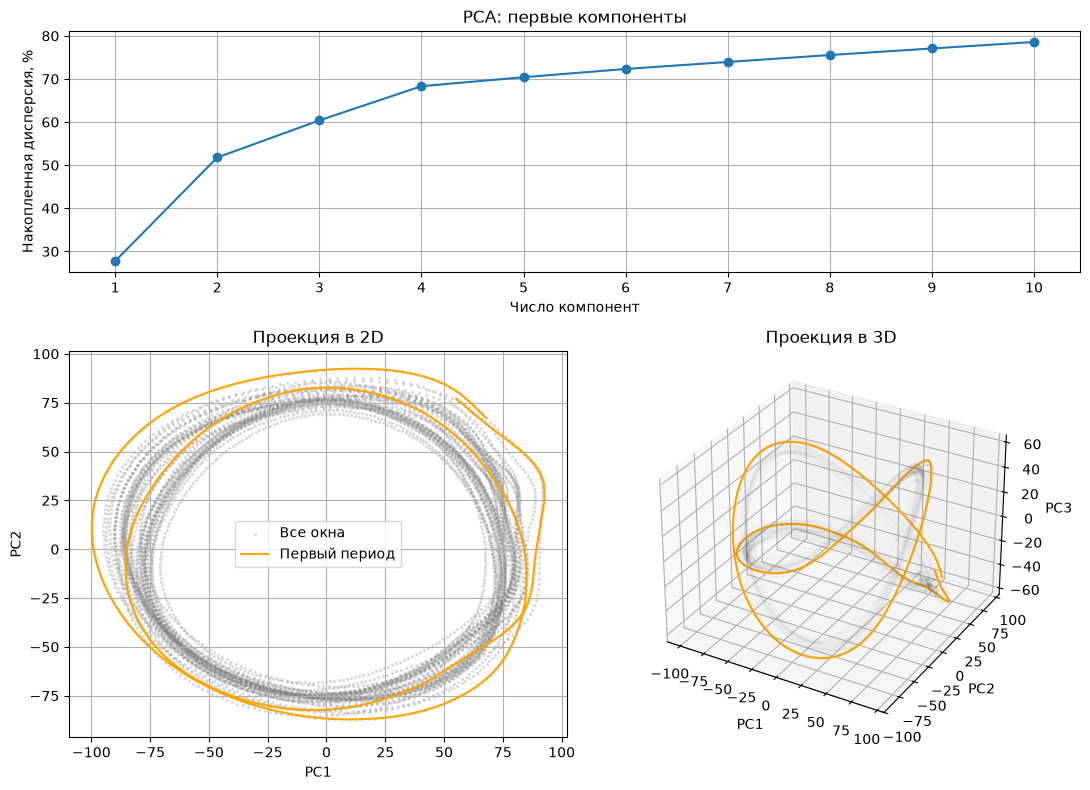

In [5]:
fig = plt.figure(figsize=(11, 8))
layout = fig.add_gridspec(2, 2, height_ratios=[1, 1.6])
ax_variance = fig.add_subplot(layout[0, :])
components = np.arange(1, min(10, WINDOW) + 1)
cumulative = np.cumsum(pca.explained_variance_ratio_)
ax_variance.plot(components, 100 * cumulative[components - 1], 'o-')
ax_variance.set(xlabel='Число компонент', ylabel='Накопленная дисперсия, %',
                title='PCA: первые компоненты')
ax_variance.set_xticks(components)

ax_2d = fig.add_subplot(layout[1, 0])
ax_2d.scatter(X_all[:, 0], X_all[:, 1], color='grey', s=2, alpha=0.2, label='Все окна')
ax_2d.plot(X_all[:period, 0], X_all[:period, 1], color='orange', label='Первый период')
ax_2d.set(xlabel='PC1', ylabel='PC2', title='Проекция в 2D')
ax_2d.legend()

ax_3d = fig.add_subplot(layout[1, 1], projection='3d')
ax_3d.scatter(X_all[:, 0], X_all[:, 1], X_all[:, 2], color='grey', s=2, alpha=0.15)
ax_3d.plot(X_all[:period, 0], X_all[:period, 1], X_all[:period, 2], color='orange')
ax_3d.set(xlabel='PC1', ylabel='PC2', zlabel='PC3', title='Проекция в 3D')
fig.tight_layout()
plt.show()

## 4. Начальные фазы

Для первых $T$ окон задаём равномерные начальные оценки фаз:

$$\widetilde\varphi_j=2\pi\frac{j-1}{T},\qquad j=1,\ldots,T.$$

Правило начальной разметки в статье не указано. Для регрессии используем пары:

$$\underbrace{\widetilde\varphi_j}_{\text{вход регрессии}}
\quad\longrightarrow\quad
\underbrace{\mathbf x_j}_{\text{ответ регрессии}}.$$

Для оценки модели, выбора размерности и поиска фазы используем равномерную сетку из `N_PHASES` узлов в $[0,2\pi)$.

In [6]:
seed_points = X_all[:period]
seed_phases = 2 * np.pi * np.arange(period) / period

## 5. Средняя фазовая траектория

По парам $(\widetilde\varphi_j,\mathbf x_j)$ регрессия Надарая—Ватсона оценивает условное среднее PCA-координат при заданной фазе:

$$\mathbf m(\varphi)=\mathbb E[\mathbf x\mid\varphi]
=\frac{\sum_j\mathbf x_j K\!\left(\rho(\widetilde\varphi_j,\varphi)/h\right)}
{\sum_j K\!\left(\rho(\widetilde\varphi_j,\varphi)/h\right)}.\tag{3}$$

Используем RBF-ядро и полуметрику фаз:

$$K(r)=\exp(-\gamma r^2),\qquad r=\rho(\varphi,\psi)/h, \qquad
\rho(\varphi,\psi)=\frac{1-\cos(\varphi-\psi)}2.$$

Для оценки разброса вычисляем взвешенное среднее евклидовых расстояний до $\mathbf m(\varphi)$:

$$D(\varphi)=
\frac{\sum_j\|\mathbf x_j-\mathbf m(\varphi)\|_2
K\!\left(\rho(\widetilde\varphi_j,\varphi)/h\right)}
{\sum_jK\!\left(\rho(\widetilde\varphi_j,\varphi)/h\right)}.\tag{4}$$

Это не совсем дисперсия

In [7]:
def phase_distance(phi, psi):
    return (1 - np.cos(phi - psi)) / 2


def kernel_weights(grid, phases, h, gamma):
    distance = phase_distance(grid[:, None], phases[None, :])
    log_weights = -gamma * (distance / h)**2
    log_weights -= log_weights.max(axis=1, keepdims=True)
    weights = np.exp(log_weights)
    return weights / weights.sum(axis=1, keepdims=True)


def fit_trajectory(points, phases, grid, h, gamma):
    weights = kernel_weights(grid, phases, h, gamma)
    mean = weights @ points
    radius = (weights * cdist(mean, points)).sum(axis=1)
    return mean, radius

## 6. Выбор размерности

Для каждого $p$ оцениваем $\mathbf m_p$ и $D_p$ по первым $p$ компонентам PCA. Определяем фазы, для которых пересекаются области разброса вокруг точек средней траектории:

$$\Phi(p)=\left\{\varphi:\exists\psi,\quad
\|\mathbf m_p(\varphi)-\mathbf m_p(\psi)\|_2\le D_p(\varphi)+D_p(\psi),\quad
\frac\pi2\le|\varphi-\psi|\le\frac{3\pi}2\right\}.\tag{5}$$

Выбираем размерность, минимизирующую число таких фаз:

$$\widehat p\in\arg\min_{p\in\{1,\ldots,n\}}|\Phi(p)|.\tag{6}$$


Проверяем все $p=1,\ldots,n$; при равных минимумах выбираем меньшее $p$:

In [8]:
def dimension_scores(points, phases, grid, h, gamma):
    weights = kernel_weights(grid, phases, h, gamma)
    means = weights @ points
    n_features = points.shape[1]
    scores = np.empty(n_features, dtype=int)
    radii = np.empty((n_features, len(grid)))
    phase_gap = np.abs(grid[:, None] - grid[None, :])
    far_phases = (phase_gap >= np.pi / 2) & (phase_gap <= 3 * np.pi / 2)

    for p in range(1, n_features + 1):
        mean = means[:, :p]
        radius = (weights * cdist(mean, points[:, :p])).sum(axis=1)
        radii[p - 1] = radius
        distances = cdist(mean, mean)
        ambiguous = far_phases & (distances <= radius[:, None] + radius[None, :])
        scores[p - 1] = ambiguous.any(axis=1).sum()

    return scores, means, radii

scores, means, radii = dimension_scores(seed_points, seed_phases, phase_grid, BANDWIDTH, GAMMA)
p_selected = int(np.argmin(scores) + 1)
X = X_all[:, :p_selected]
initial_mean = means[:, :p_selected]
initial_radius = radii[p_selected - 1]
print(f'Выбрана размерность p = {p_selected}; неоднозначных фаз: {scores[p_selected - 1]}')

Выбрана размерность p = 4; неоднозначных фаз: 0


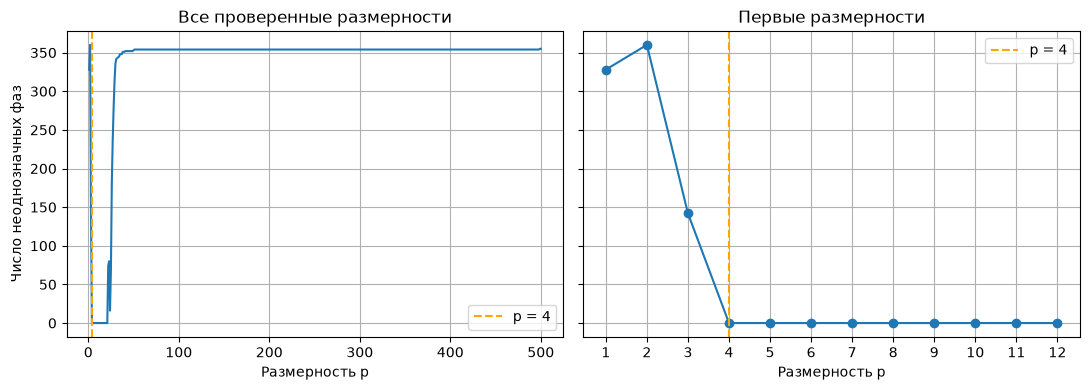

In [9]:
dimensions = np.arange(1, WINDOW + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].plot(dimensions, scores)
axes[0].set(title='Все проверенные размерности', xlabel='Размерность p',
            ylabel='Число неоднозначных фаз')
zoom = min(12, WINDOW)
axes[1].plot(dimensions[:zoom], scores[:zoom], 'o-')
axes[1].set(title='Первые размерности', xlabel='Размерность p')
axes[1].set_xticks(dimensions[:zoom])
for ax in axes:
    ax.axvline(p_selected, color='orange', linestyle='--', label=f'p = {p_selected}')
    ax.legend()
fig.tight_layout()
plt.show()

## 7. Оценка фазы

Для очередного окна $\mathbf x_i$ определяем множество допустимых фаз:

$$\Phi_i=\{\varphi:\|\mathbf x_i-\mathbf m(\varphi)\|_2\le D(\varphi)\}.\tag{15}$$

В пределах одного периода предполагается монотонный рост фазы:

$$t>t'\ \Longrightarrow\ \varphi_t>\varphi_{t'},\tag{7}$$

Для соседних точек предполагается близость фаз:

$$\|\mathbf x-\mathbf x'\|_2<\varepsilon
\ \Longrightarrow\ |\varphi-\varphi'|<\delta.\tag{8}$$

Порог $\delta$ в (8) отдельно не проверяем: близость фаз учитываем штрафом $L_2$. Для последовательной обработки в (9)–(10) сравниваем проверяемую фазу $\varphi$ с последней найденной фазой $\varphi_{\rm prev}$.

**$L_1$: уменьшение фазы.** Штраф без допуска и с допуском $\delta_\varphi$:

$$L_1^{(0)}(\varphi)=\rho(\varphi_{\rm prev},\varphi)
[\varphi_{\rm prev}-\varphi\ge0],\tag{9}$$

$$L_1(\varphi)=\rho(\varphi_{\rm prev},\varphi)
[\varphi_{\rm prev}-\varphi\ge\delta_\varphi].\tag{10}$$

**$L_2$: различие фаз соседних окон.** Используем ранее найденные фазы окон в $\varepsilon$-окрестности текущей точки:

$$L_2(\varphi)=\sum_{j<i:\,\|\mathbf x_i-\mathbf x_j\|_2<\varepsilon}
\rho(\varphi,\widehat\varphi_j).\tag{11}$$

**$L_3$: отклонение от средней траектории.** Расстояние нормируем на $D(\varphi)$:

$$L_3(\varphi)=\frac{\|\mathbf x_i-\mathbf m(\varphi)\|_2}{D(\varphi)}.\tag{12}$$

Оценку фазы находим минимизацией взвешенной суммы штрафов:

$$\widehat\varphi_i=\arg\min_{\varphi\in\Phi_i}
\sum_{l=1}^3\lambda_lL_l(\varphi),\qquad
\sum_{l=1}^3\lambda_l=1.\tag{13}$$

In [10]:
def phase_losses(phases, distances, radii, previous_phase, neighbour_phases, delta_phi):
    loss1 = np.where(previous_phase - phases >= delta_phi,
                     phase_distance(previous_phase, phases), 0)
    loss2 = phase_distance(neighbour_phases[:, None], phases[None, :]).sum(axis=0)
    loss3 = distances / np.maximum(radii, np.finfo(float).eps)
    return np.vstack([loss1, loss2, loss3])

## 8. Алгоритм

**Вход:** PCA-координаты окон $X$, период $T$, сетка фаз $G$ и параметры $h,\gamma,\varepsilon,\delta_\varphi,\lambda_l$.

**1. Начальная модель.** Задаём обучающие пары:

$$S_0=\left\{\left(2\pi\frac{j-1}{T},\mathbf x_j\right)\right\}_{j=1}^{T}.$$

По парам $(\theta_j,\mathbf x_j)\in S_0$ вычисляем:

$$w_j(\varphi)\propto e^{-\gamma[\rho(\theta_j,\varphi)/h]^2},\quad
\sum_jw_j(\varphi)=1,\qquad
\rho(a,b)=\frac{1-\cos(a-b)}2,$$

$$\mathbf m(\varphi)=\sum_jw_j(\varphi)\mathbf x_j,\qquad
D(\varphi)=\sum_jw_j(\varphi)\|\mathbf x_j-\mathbf m(\varphi)\|_2.$$

**2. Первое окно.**

$$\widehat\varphi_1=\arg\min_{\varphi\in G}\|\mathbf x_1-\mathbf m(\varphi)\|_2,
\qquad\varphi_{\rm prev}\leftarrow\widehat\varphi_1.$$

**3. Для каждого окна $i=2,\ldots,k$.**

$$\Phi_i=\{\varphi\in G:\|\mathbf x_i-\mathbf m(\varphi)\|_2\le D(\varphi)\}.$$


Находим соседей с ранее оценёнными фазами:

$$\mathcal N_i=\{j<i:\widehat\varphi_j\in G,\quad
\|\mathbf x_i-\mathbf x_j\|_2<\varepsilon\}.$$

Вычисляем штрафы и выбираем фазу:

$$\begin{aligned}
L_1(\varphi)&=\rho(\varphi_{\rm prev},\varphi)
[\varphi_{\rm prev}-\varphi\ge\delta_\varphi],\\
L_2(\varphi)&=\sum_{j\in\mathcal N_i}\rho(\varphi,\widehat\varphi_j),\\
L_3(\varphi)&=\frac{\|\mathbf x_i-\mathbf m(\varphi)\|_2}{D(\varphi)},\\
\widehat\varphi_i&=\arg\min_{\varphi\in\Phi_i}\sum_{l=1}^3\lambda_lL_l(\varphi).
\end{aligned}$$



**4. Обновление модели.** Если текущая фаза отличается от предыдущей найденной больше чем на $7\pi/4$, пересчитываем $\mathbf m$ и $D$. Используем окна первого периода с исходными фазами и все обработанные окна после него с найденными фазами.

После проверки запоминаем текущую фазу как предыдущую и переходим к следующему окну

In [11]:
def estimate_phases(X, grid, initial_mean, initial_radius, h, gamma,
                    epsilon, delta_phi, lambdas, seed_phases):
    phases = np.full(len(X), np.nan)
    mean = initial_mean.copy()
    radius = initial_radius.copy()
    update_indices = []
    seed_length = len(seed_phases)

    for i, point in enumerate(X):
        distances = np.linalg.norm(mean - point, axis=1)
        if i == 0:
            phase = grid[np.argmin(distances)]
        else:
            candidates = np.flatnonzero(distances <= radius)
            if len(candidates) == 0:
                continue
            known = np.isfinite(phases[:i])
            nearby = np.linalg.norm(X[:i] - point, axis=1) < epsilon
            neighbour_phases = phases[:i][known & nearby]
            losses = phase_losses(grid[candidates], distances[candidates], radius[candidates],
                                  previous_phase, neighbour_phases, delta_phi)
            phase = grid[candidates[np.argmin(lambdas @ losses)]]

        phases[i] = phase
        if i > 0 and abs(phase - previous_phase) > 7 * np.pi / 4:
            known = np.isfinite(phases[seed_length:i + 1])
            model_points = np.vstack([X[:seed_length], X[seed_length:i + 1][known]])
            model_phases = np.r_[seed_phases, phases[seed_length:i + 1][known]]
            mean, radius = fit_trajectory(model_points, model_phases, grid, h, gamma)
            update_indices.append(i)
        previous_phase = phase

    return phases, mean, radius, np.asarray(update_indices, dtype=int)


phases, final_mean, final_radius, updates = estimate_phases(
    X, phase_grid, initial_mean, initial_radius,
    BANDWIDTH, GAMMA, EPSILON, DELTA_PHI, LAMBDAS, seed_phases,
)

### Изменение разброса

Сравниваем $D(\varphi)$ по первому периоду и после последнего обновления модели.

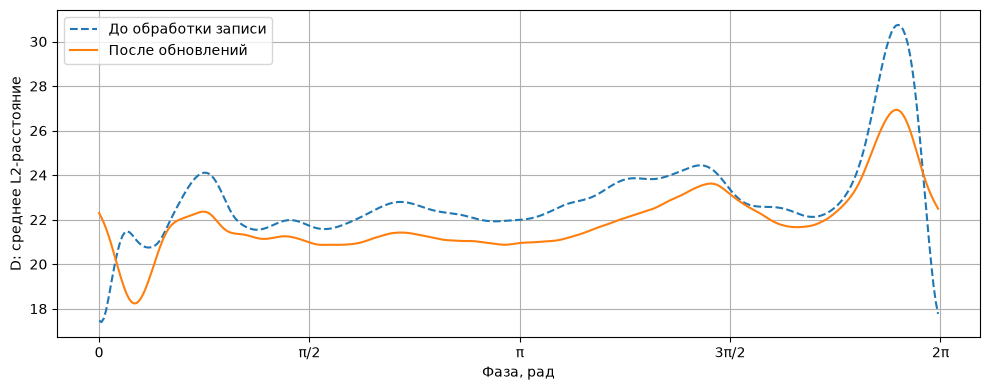

In [12]:
plt.plot(phase_grid, initial_radius, '--', label='До обработки записи')
plt.plot(phase_grid, final_radius, label='После обновлений')
plt.xlabel('Фаза, рад')
plt.ylabel('D: среднее L2-расстояние')
plt.xticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
           ['0', 'π/2', 'π', '3π/2', '2π'])
plt.legend()
plt.tight_layout()
plt.show()

## Результат


In [13]:
valid = np.isfinite(phases)
pd.Series({
    'Период, отсчёты': period,
    'Размерность p': p_selected,
    'Всего окон': len(X),
    'Окон без допустимой фазы': int((~valid).sum()),
    'Обновлений модели': len(updates),
})

Период, отсчёты              461
Размерность p                  4
Всего окон                  8741
Окон без допустимой фазы       0
Обновлений модели             19
dtype: int64

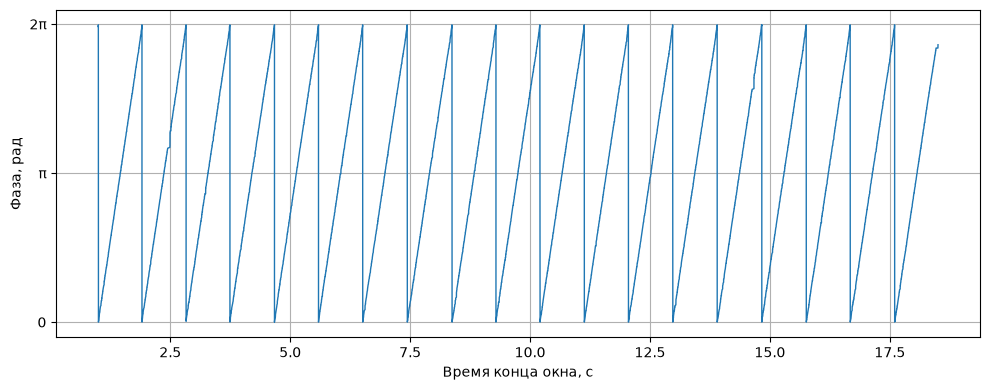

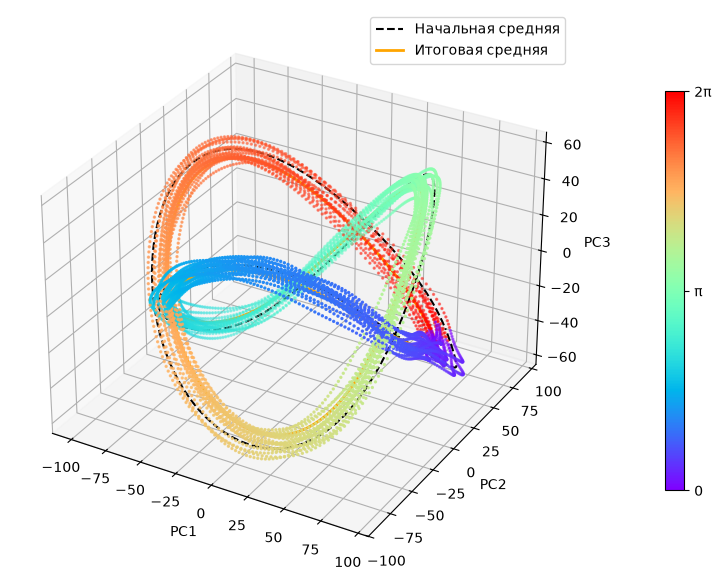

In [14]:
plt.plot(window_time, phases, linewidth=1)
plt.xlabel('Время конца окна, с')
plt.ylabel('Фаза, рад')
plt.yticks([0, np.pi, 2 * np.pi], ['0', 'π', '2π'])
plt.tight_layout()
plt.show()

fig = plt.figure(figsize=(8, 6))
if p_selected >= 3:
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(X[valid, 0], X[valid, 1], X[valid, 2],
                         c=phases[valid], cmap='rainbow', vmin=0, vmax=2 * np.pi, s=2)
    if (~valid).any():
        ax.scatter(X[~valid, 0], X[~valid, 1], X[~valid, 2],
                   color='grey', s=4, label='Фаза не найдена')
    ax.plot(initial_mean[:, 0], initial_mean[:, 1], initial_mean[:, 2],
            color='black', linestyle='--', linewidth=1.5, label='Начальная средняя')
    ax.plot(final_mean[:, 0], final_mean[:, 1], final_mean[:, 2],
            color='orange', linewidth=2, label='Итоговая средняя')
    ax.set(xlabel='PC1', ylabel='PC2', zlabel='PC3')
else:
    ax = fig.add_subplot(111)
    second = X[:, 1] if p_selected == 2 else np.zeros(len(X))
    mean_second = final_mean[:, 1] if p_selected == 2 else np.zeros(len(final_mean))
    scatter = ax.scatter(X[valid, 0], second[valid], c=phases[valid],
                         cmap='rainbow', vmin=0, vmax=2 * np.pi, s=2)
    if (~valid).any():
        ax.scatter(X[~valid, 0], second[~valid], color='grey', s=4, label='Фаза не найдена')
    initial_second = initial_mean[:, 1] if p_selected == 2 else np.zeros(len(initial_mean))
    ax.plot(initial_mean[:, 0], initial_second, color='black',
            linestyle='--', linewidth=1.5, label='Начальная средняя')
    ax.plot(final_mean[:, 0], mean_second, color='orange', label='Итоговая средняя')
    ax.set(xlabel='PC1', ylabel='PC2' if p_selected == 2 else '0')
ax.legend()
colorbar = fig.colorbar(scatter, ax=ax, shrink=0.7, pad=0.12)
colorbar.set_ticks([0, np.pi, 2 * np.pi], labels=['0', 'π', '2π'])
fig.tight_layout()
plt.show()